# Review Sentiment Analyzer (Deep Learning)

This notebook classifies social-media reviews/comments as **negative**, **neutral** or **positive** using a
pre-trained **transformer** (RoBERTa fine-tuned on ~124M tweets), then analyses the results by platform and over time.


## 1. Setup

In [ ]:
# Run once (remove the leading '#' if packages are missing)
#%pip install -q transformers torch pandas numpy matplotlib seaborn scikit-learn accelerate

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from transformers import pipeline
from datasets import Dataset

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

# ---- Configuration -------------------------------------------------------
DATA_PATH   = "sample_data.csv"      # change if your file lives elsewhere
TEXT_COL    = "comment"
MODEL_ID    = "cardiffnlp/twitter-roberta-base-sentiment-latest"
BATCH_SIZE  = 16
MAX_LEN     = 128                    # social posts are short; 128 tokens is plenty
LOW_CONF    = 0.60                   # below this, flag a prediction for human review
LABELS      = ["negative", "neutral", "positive"]
PALETTE     = {"negative": "#d9534f", "neutral": "#9aa0a6", "positive": "#2e9d5b"}

DEVICE = 0 if torch.cuda.is_available() else -1
print(f"Torch {torch.__version__} | running on {'GPU' if DEVICE == 0 else 'CPU'}")

Torch 2.14.1+cpu | running on CPU


## 2. Load and explore the data

In [27]:
df = pd.read_csv(DATA_PATH, parse_dates=["date"])

print(f"{len(df)} rows, columns: {list(df.columns)}")
print("Missing values:\n", df.isna().sum().to_string())
print("Duplicate comments:", df[TEXT_COL].duplicated().sum())
df.head()

20 rows, columns: ['platform', 'date', 'comment', 'sentiment']
Missing values:
 platform     0
date         0
comment      0
sentiment    0
Duplicate comments: 0


,platform,date,comment,sentiment
0,Twitter,2026-01-06,"Just switched to the new app and wow, so much faster than before!",positive
1,Instagram,2026-01-06,Love the redesign 😍 way easier to find what I need,positive
2,Twitter,2026-02-06,App keeps crashing every time I try to check out. So frustrating.,negative
3,Facebook,2026-02-06,"Customer support was super helpful when I had an issue, thanks!",positive
4,Twitter,2026-03-06,"meh, update didn't really change much for me",negative


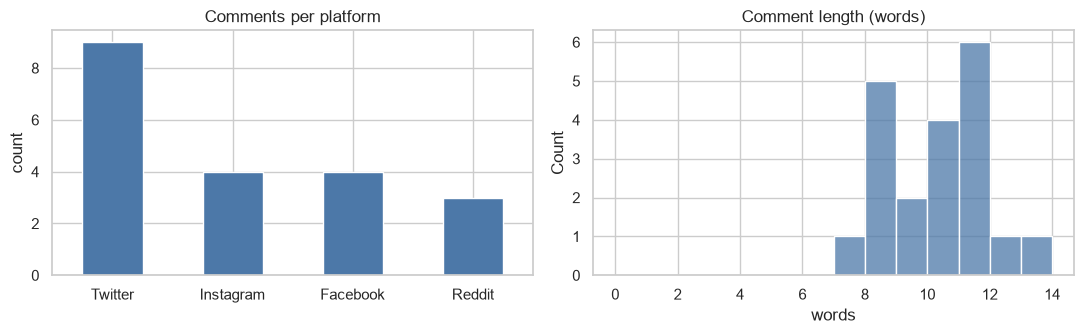

In [3]:
df["n_words"] = df[TEXT_COL].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df["platform"].value_counts().plot.bar(ax=axes[0], color="#4c78a8", rot=0)
axes[0].set_title("Comments per platform"); axes[0].set_xlabel(""); axes[0].set_ylabel("count")

sns.histplot(df["n_words"], bins=range(0, df["n_words"].max() + 2), ax=axes[1], color="#4c78a8")
axes[1].set_title("Comment length (words)"); axes[1].set_xlabel("words")
plt.tight_layout(); plt.show()

## 3. Text normalisation

Transformers need very little cleaning. We deliberately **keep** emoji, punctuation and capitalisation
("AGAIN", "!!") because they carry sentiment. We only replace user handles and URLs with placeholders, which is the
same preprocessing the model saw during training.

In [4]:
def normalise(text: str) -> str:
    text = str(text).strip()
    text = re.sub(r"@\w+", "@user", text)            # handles -> @user
    text = re.sub(r"https?://\S+", "http", text)     # URLs    -> http
    text = re.sub(r"\s+", " ", text)                 # collapse whitespace
    return text

df["clean_text"] = df[TEXT_COL].map(normalise)
df[[TEXT_COL, "clean_text"]].head(3)

,comment,clean_text
0,"Just switched to the new app and wow, so much ...","Just switched to the new app and wow, so much ..."
1,Love the redesign 😍 way easier to find what I ...,Love the redesign 😍 way easier to find what I ...
2,App keeps crashing every time I try to check o...,App keeps crashing every time I try to check o...


## 4. Load the model and predict

The first run downloads the weights (~500 MB) from the Hugging Face Hub; after that they are cached.
`top_k=None` makes the pipeline return the probability of **every** class, not just the winner, so we can measure confidence.

In [ ]:
clf = pipeline(
    "text-classification",
    model=MODEL_ID,
    tokenizer=MODEL_ID,
    top_k=None,
    device=DEVICE,
)
print("Model labels:", clf.model.config.id2label)

In [10]:
# Some checkpoints expose generic names (LABEL_0/1/2); map them to readable ones.
GENERIC = {"LABEL_0": "negative", "LABEL_1": "neutral", "LABEL_2": "positive"}

def predict(texts, batch_size=BATCH_SIZE) -> pd.DataFrame:
    """Return a DataFrame of class probabilities + predicted label + confidence."""
    outputs = clf(list(texts), batch_size=batch_size, truncation=True, max_length=MAX_LEN)
    rows = []
    for scores in outputs:
        probs = {GENERIC.get(s["label"], s["label"]).lower(): s["score"] for s in scores}
        rows.append({lab: probs.get(lab, 0.0) for lab in LABELS})
    out = pd.DataFrame(rows)
    out["sentiment"] = out[LABELS].idxmax(axis=1)
    out["confidence"] = out[LABELS].max(axis=1)
    return out

preds = predict(df["clean_text"])
result = pd.concat([df.reset_index(drop=True), preds], axis=1)
result["net_score"] = result["positive"] - result["negative"]   # -1 (very negative) .. +1 (very positive)
result["needs_review"] = result["confidence"] < LOW_CONF
result[["platform", TEXT_COL, "sentiment", "confidence"]].round(3)

,platform,comment,sentiment,confidence
0,Twitter,"Just switched to the new app and wow, so much ...",positive,0.978
1,Instagram,Love the redesign 😍 way easier to find what I ...,positive,0.979
2,Twitter,App keeps crashing every time I try to check o...,negative,0.923
3,Facebook,Customer support was super helpful when I had ...,positive,0.910
4,Twitter,"meh, update didn't really change much for me",negative,0.697
5,Reddit,"Been using this product for a year now, still ...",positive,0.952
6,Instagram,Why did you remove the dark mode option?? brin...,negative,0.700
7,Twitter,"Shipping was way faster than I expected, impre...",positive,0.983
8,Facebook,"Terrible experience, waited 3 weeks for a refund",negative,0.939
9,Twitter,"the new checkout flow is so smooth now, nice w...",positive,0.978


## 5. Analyse the results

### 5.1 Overall sentiment distribution

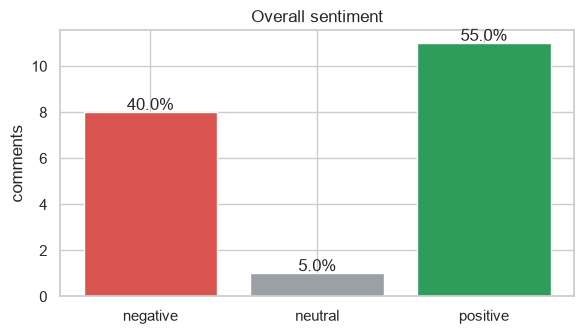

Average net sentiment score: +0.16  (range -1 to +1)


In [11]:
counts = result["sentiment"].value_counts().reindex(LABELS, fill_value=0)
pct = (counts / counts.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(counts.index, counts.values, color=[PALETTE[l] for l in counts.index])
for b, p in zip(bars, pct):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.1, f"{p}%", ha="center")
ax.set_title("Overall sentiment"); ax.set_ylabel("comments")
plt.tight_layout(); plt.show()
print(f"Average net sentiment score: {result['net_score'].mean():+.2f}  (range -1 to +1)")

### 5.2 By platform

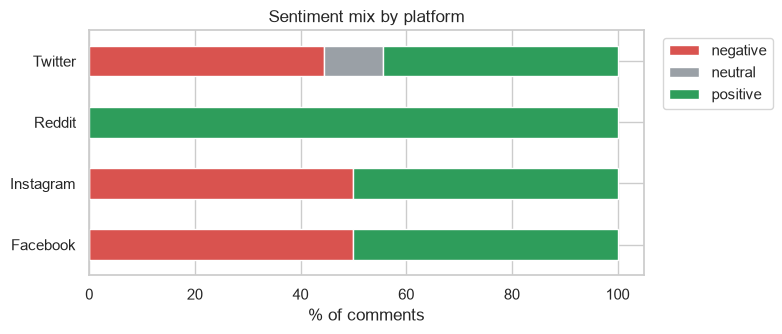

,comments,avg_net_score,avg_confidence
platform,,,
Facebook,4,0.03,0.89
Twitter,9,0.07,0.89
Instagram,4,0.08,0.90
Reddit,3,0.69,0.72


In [12]:
by_platform = (
    result.groupby(["platform", "sentiment"]).size()
          .unstack(fill_value=0).reindex(columns=LABELS, fill_value=0)
)
share = by_platform.div(by_platform.sum(axis=1), axis=0) * 100

ax = share.plot.barh(stacked=True, figsize=(8, 3.5), color=[PALETTE[l] for l in LABELS])
ax.set_xlabel("% of comments"); ax.set_ylabel(""); ax.set_title("Sentiment mix by platform")
ax.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

summary = result.groupby("platform").agg(
    comments=("sentiment", "size"),
    avg_net_score=("net_score", "mean"),
    avg_confidence=("confidence", "mean"),
).round(2).sort_values("avg_net_score")
summary

### 5.3 Trend over time
Daily average of the net sentiment score (positive probability minus negative probability).
With few comments per day the line will be noisy, so treat it as directional.

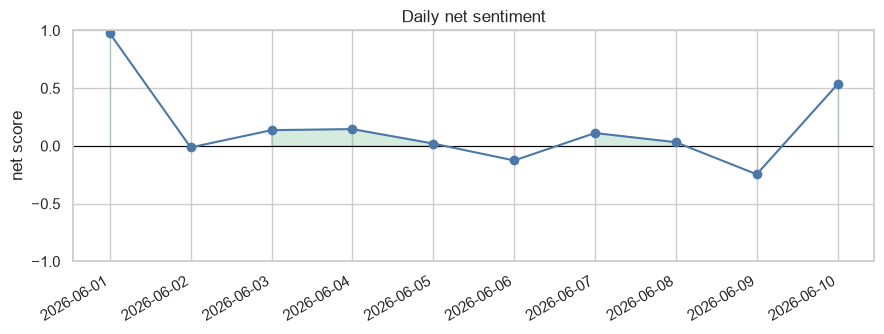

In [13]:
daily = result.groupby("date").agg(net=("net_score", "mean"), n=("net_score", "size")).reset_index()

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.axhline(0, color="black", lw=0.8)
ax.plot(daily["date"], daily["net"], marker="o", color="#4c78a8")
ax.fill_between(daily["date"], daily["net"], 0, where=daily["net"] >= 0, color=PALETTE["positive"], alpha=0.2)
ax.fill_between(daily["date"], daily["net"], 0, where=daily["net"] < 0,  color=PALETTE["negative"], alpha=0.2)
ax.set_ylim(-1, 1); ax.set_title("Daily net sentiment"); ax.set_ylabel("net score")
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

### 5.4 Most negative comments (what to fix first)

In [14]:
pd.set_option("display.max_colwidth", 120)
result.nsmallest(5, "net_score")[["platform", "date", TEXT_COL, "negative"]].round(3)

,platform,date,comment,negative
11,Instagram,2026-06-06,"Worst update ever, app is basically unusable now",0.954
8,Facebook,2026-06-05,"Terrible experience, waited 3 weeks for a refund",0.939
17,Twitter,2026-06-09,App crashed AGAIN. third time this week.,0.934
14,Twitter,2026-06-08,"Customer service ignored my email for a week, not okay",0.923
2,Twitter,2026-06-02,App keeps crashing every time I try to check out. So frustrating.,0.923


### 5.5 Low-confidence predictions (candidates for human review)

In [15]:
review = result[result["needs_review"]].sort_values("confidence")
print(f"{len(review)} of {len(result)} predictions are below {LOW_CONF:.0%} confidence")
review[[TEXT_COL, "sentiment", "confidence"] + LABELS].round(2)

1 of 20 predictions are below 60% confidence


,comment,sentiment,confidence,negative,neutral,positive
16,"It's fine, nothing special but gets the job done",positive,0.5,0.06,0.44,0.5


## 6. Sanity check against hand labels



Accuracy: 85.00%

              precision    recall  f1-score   support

    negative       0.88      1.00      0.93         7
     neutral       1.00      0.25      0.40         4
    positive       0.82      1.00      0.90         9

    accuracy                           0.85        20
   macro avg       0.90      0.75      0.74        20
weighted avg       0.87      0.85      0.81        20



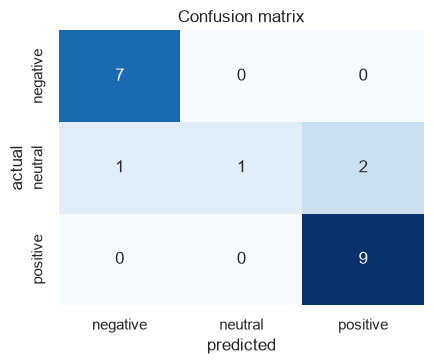

,comment,true_label,sentiment,confidence
4,"meh, update didn't really change much for me",neutral,negative,0.70
10,"Honestly not bad, does what it says on the tin",neutral,positive,0.72
16,"It's fine, nothing special but gets the job done",neutral,positive,0.50


In [16]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

DEMO_LABELS = [
    "positive", "positive", "negative", "positive", "neutral",
    "positive", "negative", "positive", "negative", "positive",
    "neutral",  "negative", "positive", "negative", "negative",
    "positive", "neutral",  "negative", "positive", "neutral",
]

if "label" in result.columns:
    result["true_label"] = result["label"].str.lower()
elif len(result) == len(DEMO_LABELS):
    result["true_label"] = DEMO_LABELS
else:
    result["true_label"] = np.nan
    print("No labels available: skipping evaluation.")

if result["true_label"].notna().any():
    y_true, y_pred = result["true_label"], result["sentiment"]
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.2%}\n")
    print(classification_report(y_true, y_pred, labels=LABELS, zero_division=0))

    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    fig, ax = plt.subplots(figsize=(4.5, 3.8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=LABELS, yticklabels=LABELS, ax=ax)
    ax.set_xlabel("predicted"); ax.set_ylabel("actual"); ax.set_title("Confusion matrix")
    plt.tight_layout(); plt.show()

    wrong = result[result["true_label"] != result["sentiment"]]
    display(wrong[[TEXT_COL, "true_label", "sentiment", "confidence"]].round(2))

## 7. Try your own reviews

In [17]:
def analyze(*reviews: str) -> pd.DataFrame:
    """Score one or more reviews and print a readable summary."""
    texts = [normalise(r) for r in reviews]
    out = predict(texts)
    out.insert(0, "review", reviews)
    for _, r in out.iterrows():
        print(f"{r['sentiment'].upper():9s} ({r['confidence']:.0%})  {r['review']}")
    return out.round(3)

analyze(
    "Absolutely love this app, best update yet 😍",
    "Support never answered my ticket. Unacceptable.",
    "It works. Nothing more, nothing less.",
    "Great, another crash. Just what I needed today.",       # sarcasm: a known weak spot
)

POSITIVE  (99%)  Absolutely love this app, best update yet 😍
NEGATIVE  (94%)  Support never answered my ticket. Unacceptable.
POSITIVE  (81%)  It works. Nothing more, nothing less.
NEGATIVE  (48%)  Great, another crash. Just what I needed today.


,review,negative,neutral,positive,sentiment,confidence
0,"Absolutely love this app, best update yet 😍",0.005,0.007,0.987,positive,0.987
1,Support never answered my ticket. Unacceptable.,0.935,0.059,0.006,negative,0.935
2,"It works. Nothing more, nothing less.",0.019,0.172,0.809,positive,0.809
3,"Great, another crash. Just what I needed today.",0.478,0.208,0.314,negative,0.478


## 8. Export results

In [18]:
export_cols = ["platform", "date", TEXT_COL, "sentiment", "confidence",
               "negative", "neutral", "positive", "net_score", "needs_review"]
result[export_cols].round(4).to_csv("sentiment_results.csv", index=False)
print("Saved sentiment_results.csv")

Saved sentiment_results.csv
